In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import mutual_info_regression

In [ ]:
df = pd.read_csv('../data/station_shift_counts.csv', parse_dates=['ShiftDate'])
df = df.sort_values(['Station', 'ShiftDate']).reset_index(drop=True)
df['known'] = df['calls'].where(~df['Masked'])          # outage shifts count as unknown
train = df[df['ShiftDate'].dt.year <= 2024].copy() 

In [3]:
# citywide series: one value per shift
city = train.groupby('ShiftDate')['known'].sum(min_count=34)
city[train.groupby('ShiftDate')['Masked'].any()] = np.nan


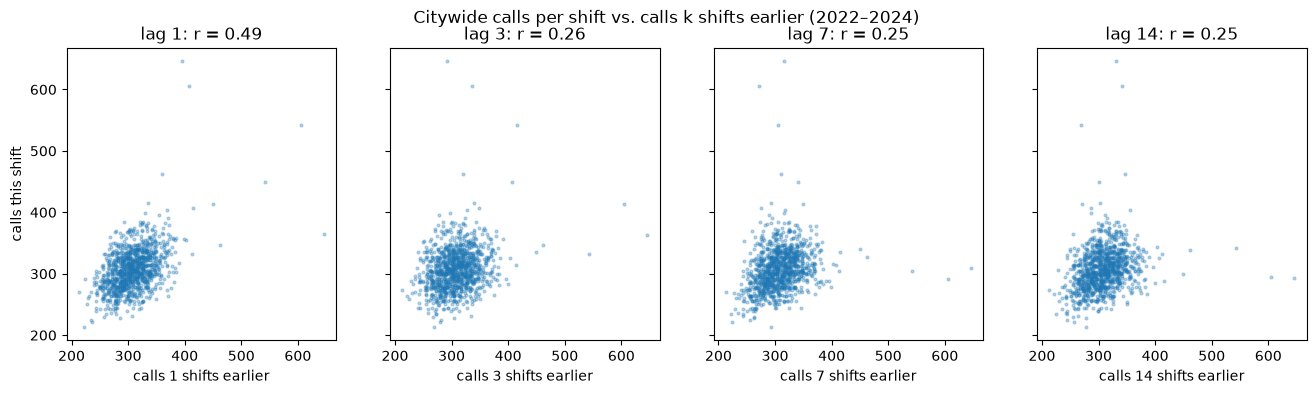

In [4]:
# ---- 1. lag plots ----
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, k in zip(axes, [1, 3, 7, 14]):
    ax.scatter(city.shift(k), city, s=4, alpha=0.3)
    ax.set_title(f'lag {k}: r = {city.corr(city.shift(k)):.2f}')
    ax.set_xlabel(f'calls {k} shifts earlier')
axes[0].set_ylabel('calls this shift')
fig.suptitle('Citywide calls per shift vs. calls k shifts earlier (2022–2024)')
plt.show()

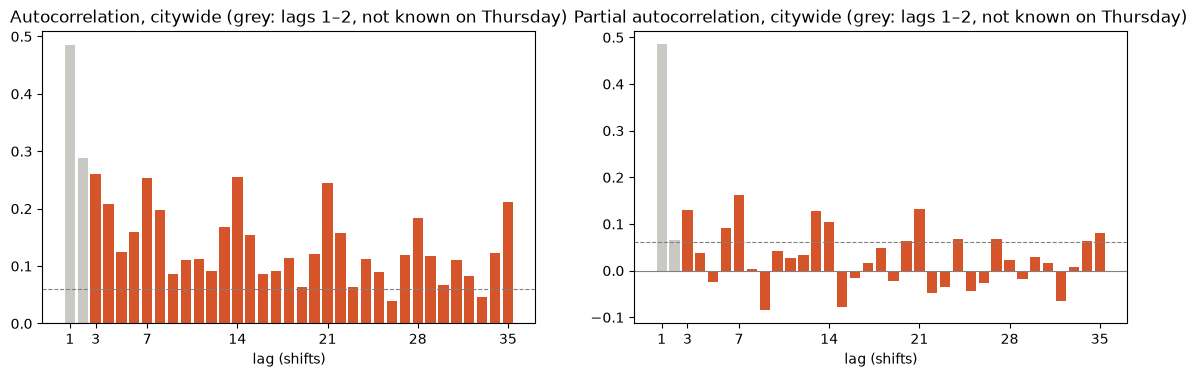

In [5]:
# ---- 2. autocorrelation and partial autocorrelation ----
def acf(s, max_lag):
    return pd.Series({k: s.corr(s.shift(k)) for k in range(1, max_lag + 1)})

def pacf(s, max_lag):
    """Partial autocorrelation: coefficient of lag k when lags 1..k are fitted together."""
    out = {}
    for k in range(1, max_lag + 1):
        X = pd.concat({j: s.shift(j) for j in range(1, k + 1)}, axis=1)
        ok = X.notna().all(axis=1) & s.notna()
        Xs, ys = (X[ok] - X[ok].mean()) / X[ok].std(), (s[ok] - s[ok].mean()) / s[ok].std()
        out[k] = LinearRegression().fit(Xs, ys).coef_[-1]
    return pd.Series(out)

max_lag = 35
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, (title, values) in zip(axes, [('Autocorrelation', acf(city, max_lag)), ('Partial autocorrelation', pacf(city, max_lag))]):
    colors = ['#c9c8c2' if k < 3 else '#d6542a' for k in values.index]   # lags 1-2 are not known on Thursday
    ax.bar(values.index, values.values, color=colors)
    ax.axhline(0, color='grey', linewidth=0.8)
    ax.axhline(2 / np.sqrt(city.notna().sum()), color='grey', linestyle='--', linewidth=0.8)   # rough significance line
    ax.set_xticks([1, 3, 7, 14, 21, 28, 35])
    ax.set_title(f'{title}, citywide (grey: lags 1–2, not known on Thursday)')
    ax.set_xlabel('lag (shifts)')
plt.show()

In [6]:
# ---- 3. per station: remove each station's own mean, then correlation and mutual information with each lag ----
# counts are whole numbers with many ties, which the mutual-information estimator overrates,
# so spread each count over its unit interval before comparing
rng = np.random.default_rng(0)
train['resid'] = train['known'] + rng.uniform(-0.5, 0.5, len(train)) - train.groupby('Station')['known'].transform('mean')
lags = [3, 4, 5, 6, 7, 14, 21, 28]
X = pd.concat({f'lag{k}': train.groupby('Station')['resid'].shift(k) for k in lags}, axis=1)
ok = X.notna().all(axis=1) & train['resid'].notna()
mi = pd.Series(mutual_info_regression(X[ok], train.loc[ok, 'resid'], random_state=0), index=X.columns)
station_acf = pd.Series({f'lag{k}': train['resid'].corr(train.groupby('Station')['resid'].shift(k)) for k in lags})
pd.DataFrame({'autocorrelation': station_acf, 'mutual information': mi}).round(3)

,autocorrelation,mutual information
lag3,0.072,0.023
lag4,0.053,0.029
lag5,0.047,0.023
lag6,0.046,0.030
lag7,0.068,0.019
lag14,0.072,0.031
lag21,0.067,0.027
lag28,0.056,0.022
